# Can Market Regime Detection and Financial News Sentiment Analysis Improve Dynamic Commodity Portfolio Allocation?
### A Machine Learning Approach
**Ons Jdey and Senghak Rou · ENSAE · ML for Portfolio Management and Trading · 13 November 2026**

## 1. Introduction
Commodity returns and risks may vary with volatility, exchange rates and interest rates. Identifying market *regimes* could therefore help a portfolio adapt its return and covariance estimates. Financial news might add information beyond prices and macroeconomic indicators. We test these ideas on five commodities from three sectors: Brent crude, US natural gas, gold, silver and copper.

All strategies are long-only and rebalance monthly on the same dates under the same cost convention. Equal weighting (A) is a benchmark that assigns 20% to each commodity without optimisation. The optimised strategies (B–G) share a constrained Markowitz framework and differ in their information sets and moment estimates.

| ID | Strategy | Information conditioning the moments |
|:--|:--|:--|
| A | Equal weight | No moment estimation |
| B | Markowitz | Unconditional rolling 120-month moments |
| C / E | Regime Markowitz (KMeans / GMM) | 15 commodity + 6 FRED features |
| G | Sentiment Markowitz | Gold-news sentiment only |
| D / F | Regime + sentiment Markowitz (KMeans / GMM) | 21 market features + sentiment |

We test three hypotheses using paired Sharpe-ratio differences: **H1**, regimes improve Markowitz (C−B, E−B); **H2**, sentiment alone improves Markowitz (G−B); and **H3**, sentiment improves regime portfolios (D−C, F−E).

The contribution is a common monthly dataset and walk-forward comparison combining World Bank prices, FRED indicators and human-annotated gold news. These are retrospective price-proxy evaluations; their timing and data limitations are discussed below.

**Main results** (July 2016 – December 2018, 30 months, net of 10 bp per unit of turnover):

- **H1: suggestive but fragile.** KMeans raises the observed Sharpe ratio from 0.35 to 0.68. The paired 95% interval for the difference, [0.04, 0.81], excludes zero, but the Bonferroni-adjusted interval includes it. In 2021–2025, a newly selected and refitted KMeans model trails Markowitz by 0.10. The initial GMM gain of 0.09 also has an interval containing zero.
- **H2 and H3: not supported.** Sentiment lowers the observed Sharpe ratio alone (G−B = −0.15) and with regimes (D−C = −0.17, F−E = −0.03); all paired intervals include zero.
- **Sentiment timing.** Its correlation with gold price changes is 0.43 in the same month and −0.12 two months later, the first horizon permitted by the backtest. This does not establish why sentiment fails to improve the portfolios.

**Reproduction.** Run all cells with Python 3.12 and internet access. Inputs are downloaded from fixed revisions and checked by SHA-256; no local data files are required. The saved execution reports the main package versions shown below:
```python
%pip install numpy==2.4.4 pandas==2.3.3 scipy==1.17.1 scikit-learn==1.9.0 matplotlib==3.10.9 openpyxl==3.1.5 pyarrow==25.0.1 requests==2.34.2
```

In [1]:
from io import BytesIO
from importlib.metadata import version
import hashlib
import sys
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import PercentFormatter
from scipy.optimize import minimize
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, adjusted_rand_score
from IPython.display import display, Markdown

SEED = 42
START, END = pd.Timestamp("2006-04-01"), pd.Timestamp("2018-12-01")
TRAIN_END, MODEL_END = pd.Timestamp("2012-12-01"), pd.Timestamp("2015-12-01")
EVAL_START = pd.Timestamp("2016-07-01")
LOOKBACK, LAG, PRIOR, MIN_EFFECTIVE = 120, 2, 24, 12
GAMMA, CAP, MEAN_SHRINK, COV_SHRINK, FEE_BPS = 5.0, .60, .50, .20, 10
NAMES = list("ABCDEFG")
DESCRIPTIONS = dict(zip(NAMES, ["Equal weight", "Markowitz", "KMeans regimes", "KMeans + sentiment",
                                "GMM regimes", "GMM + sentiment", "Sentiment only"]))
COLORS = dict(zip(NAMES, ["#7f7f7f", "#111111", "#1f77b4", "#2ca02c", "#ff7f0e", "#d62728", "#9467bd"]))
plt.rcParams.update({"font.size": 10, "axes.grid": True, "grid.alpha": .2,
                     "axes.spines.top": False, "axes.spines.right": False})
print("Python", sys.version.split()[0], {p: version(p) for p in
      ["numpy", "pandas", "scipy", "scikit-learn", "matplotlib", "openpyxl", "pyarrow"]})

Python 3.12.6 {'numpy': '2.4.4', 'pandas': '2.3.3', 'scipy': '1.17.1', 'scikit-learn': '1.9.0', 'matplotlib': '3.10.9', 'openpyxl': '3.1.5', 'pyarrow': '25.0.1'}


## 2. Data sources and preprocessing

### 2.1 Commodity prices and market indicators
Prices cover January 2000 – December 2025 and are monthly averages from the [World Bank Pink Sheet](https://www.worldbank.org/en/research/commodity-markets) (nominal USD). They are benchmark prices, not futures total returns. Market indicators are four daily [FRED](https://fred.stlouisfed.org/) series: VIX (`VIXCLS`), the broad dollar index (`DTWEXBGS`), and the 10- and 2-year Treasury yields (`DGS10`, `DGS2`). They are averaged within each month, requiring at least ten valid days. The snapshots retrieved on 7 November 2026 are downloaded from [project revision `3eaa7f3`](https://github.com/onsjd/Machine-learning-for-portfolio-management/tree/3eaa7f398ac0f8cc7ea2d1a89381ad11815a900c/data) so that later vendor revisions cannot silently change the results.

In [2]:
SNAPSHOT = ("https://raw.githubusercontent.com/onsjd/Machine-learning-for-portfolio-management/"
            "3eaa7f398ac0f8cc7ea2d1a89381ad11815a900c/data/raw/")
MARKET_SOURCES = {
    "World Bank": ("world_bank_monthly.xlsx", "3c8d9d8dbb48342fdbf24777c39a8ce8964cc2fd0958f72f6779e6e4ad99cde2"),
    "VIXCLS": ("fred/VIXCLS.csv", "b587c3478ee03ccb21a8e5d7582baaa4b921ff6aaef552551f6dd9cb95a81db0"),
    "DTWEXBGS": ("fred/DTWEXBGS.csv", "1569a280c509d0e2e702c0c5fb410415e2c137748a689f430a0116dcb24bc5ed"),
    "DGS10": ("fred/DGS10.csv", "85ffdfe56808d9f340bc267c57c0d578ebae48bc73bc8763c581b891b50cac41"),
    "DGS2": ("fred/DGS2.csv", "cffee922bb4c42ad21af44f12d453c87afb52f62e6352e4aedcefc89af93ac0a"),
}

def download_verified(url, sha256):
    response = requests.get(url, timeout=90)
    response.raise_for_status()
    if hashlib.sha256(response.content).hexdigest() != sha256:
        raise ValueError(f"Integrity check failed: {url}")
    return BytesIO(response.content)

raw = {name: download_verified(SNAPSHOT + path, sha) for name, (path, sha) in MARKET_SOURCES.items()}
wb = pd.read_excel(raw["World Bank"], sheet_name="Monthly Prices", header=4)
wb = wb.loc[wb.iloc[:, 0].astype(str).str.fullmatch(r"\d{4}M\d{2}")].copy()
wb.index = pd.to_datetime(wb.iloc[:, 0], format="%YM%m")
COMMODITIES = {"Crude oil, Brent": "brent", "Natural gas, US": "natural_gas_us",
               "Gold": "gold", "Silver": "silver", "Copper": "copper"}
prices = wb[list(COMMODITIES)].rename(columns=COMMODITIES).apply(pd.to_numeric).loc["2000-01":"2025-12"]
prices.index.name = "date"
assert prices.index.equals(pd.date_range("2000-01-01", "2025-12-01", freq="MS"))
assert np.isfinite(prices).all().all() and prices.gt(0).all().all()
ret = prices.pct_change(fill_method=None).dropna()  # simple monthly price changes, used for portfolios

fred, fred_days = {}, {}
for sid in ["VIXCLS", "DTWEXBGS", "DGS10", "DGS2"]:
    daily = pd.read_csv(raw[sid], index_col=0, parse_dates=True)
    values = pd.to_numeric(daily[sid], errors="coerce").sort_index()  # holidays stay missing
    fred_days[sid] = values.resample("MS").count()
    fred[sid] = values.resample("MS").mean().where(fred_days[sid] >= 10)
fred = pd.DataFrame(fred).loc["2000-01":"2025-12"]
fred_days = pd.DataFrame(fred_days)
print("All five market sources verified.")

All five market sources verified.


### 2.2 Gold-news sentiment
We use the [SaguaroCapital redistribution](https://huggingface.co/datasets/SaguaroCapital/sentiment-analysis-in-commodity-market-gold/blob/4423810af0fddf2c91a3c9634bbb6d4afdf9d5a5/README.md) (revision `4423810`, CC BY-NC-ND 4.0) of the Sinha–Khandait corpus: gold-market headlines labelled by experts as positive, negative, neutral or none. We retain these annotations rather than train a classifier. The alternative oil-news datasets have insufficient history for this design: `polibert/oil-sentiment-headlines` begins in 2019 and uses automated labels, while the `newsdata01` snapshot covers only 2026. Neither supports the 120-month estimation windows used here.

We combine the supplied splits and impose our own chronological partition. Dates are parsed as day–month–year; undatable, out-of-window and empty records are removed. We retain one record per date–headline pair, excluding pairs with conflicting annotations. If $N_t^+$, $N_t^-$, $N_t^{\text{neutral}}$ and $N_t^{\text{none}}$ denote monthly label counts, sentiment is
$$S_t=\frac{N_t^{+}-N_t^{-}}{N_t^{+}+N_t^{-}+N_t^{\text{neutral}}+N_t^{\text{none}}}\in[-1,1].$$

In [3]:
DATASET = "SaguaroCapital/sentiment-analysis-in-commodity-market-gold"
REVISION = "4423810af0fddf2c91a3c9634bbb6d4afdf9d5a5"
NEWS_HASHES = {"train": "65b0f4ab9e6dc2009960b762285924f440f8a551d593a5120905b763c79c1b68",
               "test": "b1a169fea3241630b293391dfe879189221896274d64f2a95fa513633a87f089"}
news_url = f"https://huggingface.co/datasets/{DATASET}/resolve/{REVISION}/data/"
raw_news = pd.concat([pd.read_parquet(download_verified(news_url + f"{split}-00000-of-00001.parquet", sha))
                      .assign(source_split=split) for split, sha in NEWS_HASHES.items()], ignore_index=True)
LABELS = ["positive", "negative", "neutral", "none"]
BINARY_COLUMNS = ["Price Direction Up", "Price Direction Constant", "Price Direction Down",
                  "Asset Comparision", "Past Information", "Future Information"]
KEYS = ["date", "headline_key"]

def clean_news(raw):
    frame = raw.copy()
    frame["date"] = pd.to_datetime(frame["Dates"].astype("string").str.strip(), format="%d-%m-%Y", errors="coerce")
    frame["headline"] = frame["News"].astype("string").str.strip()
    frame["label"] = frame["Price Sentiment"].astype("string").str.strip().str.lower()
    frame["headline_key"] = frame["headline"].str.lower().str.replace(r"\s+", " ", regex=True).str.strip()
    remaining, exclusions = pd.Series(True, index=frame.index), {}
    for reason, mask in [("invalid date", frame.date.isna()),
                         ("outside window", ~frame.date.between(START, END + pd.offsets.MonthEnd(0))),
                         ("empty headline or label", frame.headline.isna() | frame.headline.eq("")
                                                      | frame.label.isna() | frame.label.eq(""))]:
        removed = remaining & mask.fillna(False)
        exclusions[reason] = int(removed.sum())
        remaining &= ~removed
    candidate = frame.loc[remaining].copy()
    assert candidate.label.isin(LABELS).all() and candidate[BINARY_COLUMNS].isin([0, 1]).all().all()
    conflicts = candidate.groupby(KEYS)[["label"] + BINARY_COLUMNS].nunique(dropna=False).gt(1).any(axis=1)
    bad = pd.MultiIndex.from_frame(candidate[KEYS]).isin(conflicts.index[conflicts])
    clean = candidate.loc[~bad].drop_duplicates(KEYS).sort_values("date", kind="stable").copy()
    exclusions["duplicate or conflicting"] = len(candidate) - len(clean)
    assert len(raw) == sum(exclusions.values()) + len(clean)
    clean["month"] = clean.date.dt.to_period("M")
    return clean, exclusions

def aggregate_news(clean):
    months = pd.period_range(START, END, freq="M")
    counts = pd.crosstab(clean["month"], clean["label"]).reindex(index=months, columns=LABELS, fill_value=0)
    total = counts.sum(axis=1)
    assert total.gt(0).all(), "Missing month: sentiment is never imputed."
    result = pd.DataFrame({"gold_news_sentiment": (counts.positive - counts.negative) / total,
                           "gold_news_count": total})
    result.index = months.to_timestamp(how="start")
    return result

news, news_exclusions = clean_news(raw_news)
monthly_news = aggregate_news(news)
assert len(raw_news) == 10570 and len(news) == 9397

### 2.3 Features and descriptive statistics
Each observation is a month. Let $P_{i,t}$ be commodity $i$'s monthly average price, $r_{i,t}=P_{i,t}/P_{i,t-1}-1$ its simple price change, and $\ell_{i,t}=\log(P_{i,t}/P_{i,t-1})$ its log change. Portfolios use $r_{i,t}$; the 15 commodity features are $\ell_{i,t}$, three-month momentum $\sum_{h=0}^{2}\ell_{i,t-h}$ and twelve-month volatility $\sqrt{12}\,\mathrm{sd}(\ell_{i,t-11},\dots,\ell_{i,t})$.

The six FRED features are log VIX, one- and three-month log changes in the dollar index, the 10-year yield, its monthly change and the 10y−2y yield spread. All windows are trailing. Dollar-index coverage starts in 2006, making April 2006 the first complete feature month. The market vector $X^M_t$ has 21 features; $X^{M+S}_t=(X^M_t,S_t)$ adds sentiment.

,
Commodity months (Jan 2000-Dec 2025),"312 x 5 assets, no missing or non-positive price"
Feature months (Apr 2006-Dec 2018),"153, no missing value"
Headlines downloaded,"10,570"
"Excluded: invalid date, outside window, empty headline or label, duplicate or conflicting",165 / 1007 / 0 / 1
Headlines retained,"9,397"
Headlines per month,14-250 (median 44)
Headlines describing past prices,96.7%


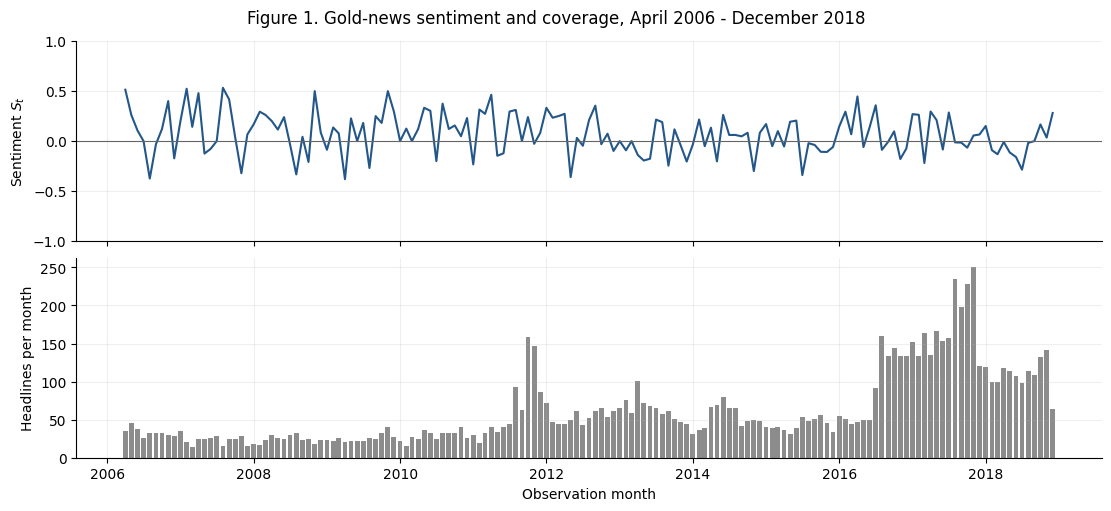

In [4]:
def market_features(price_data, macro_data):
    log_returns = np.log(price_data).diff().dropna()
    commodity = pd.concat({"r1": log_returns, "mom3": log_returns.rolling(3).sum(),
                           "vol12": log_returns.rolling(12).std() * np.sqrt(12)}, axis=1).dropna()
    commodity.columns = ["__".join(c) for c in commodity.columns]
    macro = pd.DataFrame({
        "fred_log_vix": np.log(macro_data.VIXCLS),
        "fred_dollar_return_1m": np.log(macro_data.DTWEXBGS).diff(),
        "fred_dollar_momentum_3m": np.log(macro_data.DTWEXBGS).diff(3),
        "fred_yield10_level_pp": macro_data.DGS10,
        "fred_yield10_change_1m_pp": macro_data.DGS10.diff(),
        "fred_yield_slope_10y2y_pp": macro_data.DGS10 - macro_data.DGS2})
    return commodity.join(macro).replace([np.inf, -np.inf], np.nan).dropna()

X_all = market_features(prices, fred)               # April 2006 - December 2025
common = pd.date_range(START, END, freq="MS")
X_market = X_all.loc[common]
X_sentiment = X_market.join(monthly_news[["gold_news_sentiment"]], validate="one_to_one")
S = X_sentiment["gold_news_sentiment"]
assert X_market.shape == (153, 21) and X_sentiment.shape == (153, 22)
assert np.isfinite(X_sentiment.to_numpy()).all() and fred_days.loc[common].ge(10).all().all()

display(pd.Series({
    "Commodity months (Jan 2000-Dec 2025)": f"{len(prices)} x 5 assets, no missing or non-positive price",
    "Feature months (Apr 2006-Dec 2018)": f"{len(common)}, no missing value",
    "Headlines downloaded": f"{len(raw_news):,}",
    "Excluded: " + ", ".join(news_exclusions): " / ".join(map(str, news_exclusions.values())),
    "Headlines retained": f"{len(news):,}",
    "Headlines per month": f"{monthly_news.gold_news_count.min()}-{monthly_news.gold_news_count.max()} "
                           f"(median {monthly_news.gold_news_count.median():.0f})",
    "Headlines describing past prices": f"{news['Past Information'].mean():.1%}",
}, name="").to_frame())

fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True, layout="constrained")
axes[0].plot(S.index, S, color="#235789")
axes[0].axhline(0, color=".4", linewidth=.8)
axes[0].set(ylabel="Sentiment $S_t$", ylim=(-1, 1))
axes[1].bar(monthly_news.index, monthly_news.gold_news_count, width=24, color=".55")
axes[1].set(ylabel="Headlines per month", xlabel="Observation month")
fig.suptitle("Figure 1. Gold-news sentiment and coverage, April 2006 - December 2018")
plt.show()

Monthly coverage ranges from 14 to 250 headlines, making sentiment potentially less precise in sparse months. Almost all retained headlines (96.7%) are labelled as past information. The empirical question is therefore whether their monthly balance adds useful information beyond prices; Section 4.4 examines its correlations across horizons.

## 3. Methodology and experimental design
The sequence is: construct features, estimate regime memberships, estimate conditional return moments, optimise weights, backtest and evaluate performance.

### 3.1 Chronological split and information timing

| Sample | Months | Use |
|:--|:--|:--|
| Training | Apr 2006 – Dec 2012 (81) | Fit candidate models; select GMM count |
| Validation | Jan 2013 – Dec 2015 (36) | Select KMeans count by silhouette |
| Development | Apr 2006 – Dec 2015 (117) | Refit scalers and models once, then freeze them |
| Evaluation | Jul 2016 – Dec 2018 (30) | Portfolio backtest |

Let $r_t$ be the vector of simple commodity price changes and $p_t=(p_{t,1},\dots,p_{t,k})$ the membership vector across $k$ regimes, with entries summing to one. An allocation for month $t$ uses information through $c=t-2$, allowing a full month after the observation month for publication and collection. Conditional moments use the latest 120 pairs $\{(p_{u-2},r_u):u=c-119,\dots,c\}$ and the current membership $p_c$. July 2016 is the first month with a complete window. Features are not pre-shifted: each signal is paired with a return two months later.

This lag controls the calculation's information cutoff; it does not establish historical availability of the revised data or annotations.

In [5]:
train_dates = common[common <= TRAIN_END]
valid_dates = common[(common > TRAIN_END) & (common <= MODEL_END)]
dev_dates = common[common <= MODEL_END]
test_dates = pd.date_range(EVAL_START, END, freq="MS")
signal_dates = test_dates - pd.DateOffset(months=LAG)
assert [len(d) for d in (train_dates, valid_dates, dev_dates, test_dates)] == [81, 36, 117, 30]
assert dev_dates.max() < signal_dates.min()
month = lambda d: d.strftime("%b %Y")
display(pd.DataFrame([{
    "allocation": month(t), "current signal": month(t - pd.DateOffset(months=LAG)),
    "returns used": f"{month(t - pd.DateOffset(months=LAG + LOOKBACK - 1))} - {month(t - pd.DateOffset(months=LAG))}",
    "historical signals": f"{month(t - pd.DateOffset(months=2 * LAG + LOOKBACK - 1))} - {month(t - pd.DateOffset(months=2 * LAG))}"}
    for t in test_dates[[0, -1]]]).set_index("allocation"))

,current signal,returns used,historical signals
allocation,,,
Jul 2016,May 2016,Jun 2006 - May 2016,Apr 2006 - Mar 2016
Dec 2018,Oct 2018,Nov 2008 - Oct 2018,Sep 2008 - Aug 2018


### 3.2 Regimes and the sentiment state
**KMeans** minimises within-group squared distance between standardised feature vectors. Its membership $p_{t,j}$ is binary: one for the assigned state and zero otherwise. A **Gaussian mixture model (GMM)** with diagonal component covariances instead supplies posterior membership probabilities.

For $k\in\{2,3,4\}$, we select KMeans by the highest validation silhouette and GMM by the lowest training Bayesian information criterion (BIC), using the 21 market features. The selected count is retained for each sentiment counterpart. Each scaler and model is then refitted on development data and frozen; only the rolling return moments update during evaluation.

The **sentiment-only** strategy G uses the binary state $\mathbf 1\{S_t>\mathrm{median}_{\mathrm{development}}(S)\}$. The median produces approximately balanced development states: 59 observations at or below the threshold and 58 above it. The threshold is fixed before evaluation.

In [6]:
def select_counts(data, train_idx, valid_idx):
    scaler = StandardScaler().fit(data.loc[train_idx])
    z_train, z_valid = scaler.transform(data.loc[train_idx]), scaler.transform(data.loc[valid_idx])
    rows = []
    for k in [2, 3, 4]:
        km = KMeans(n_clusters=k, n_init=30, random_state=SEED).fit(z_train)
        gm = GaussianMixture(n_components=k, covariance_type="diag", reg_covar=1e-4,
                             n_init=10, max_iter=500, random_state=SEED).fit(z_train)
        assert gm.converged_
        groups = km.predict(z_valid)
        silhouette = silhouette_score(z_valid, groups) if 1 < len(np.unique(groups)) < len(groups) else np.nan
        rows.append({"k": k, "KMeans validation silhouette": silhouette,
                     "KMeans validation groups": len(np.unique(groups)), "GMM training BIC": gm.bic(z_train)})
    table = pd.DataFrame(rows).set_index("k")
    return {"KMeans": int(table["KMeans validation silhouette"].idxmax()),
            "GMM": int(table["GMM training BIC"].idxmin())}, table

def fit_memberships(data, algorithm, k, dev_idx, seed=SEED):
    """Fit the scaler and model on development months only; return memberships for every month."""
    scaler = StandardScaler().fit(data.loc[dev_idx])
    model = (KMeans(n_clusters=k, n_init=50, random_state=seed) if algorithm == "KMeans" else
             GaussianMixture(n_components=k, covariance_type="diag", reg_covar=1e-4,
                             n_init=20, max_iter=500, random_state=seed))
    model.fit(scaler.transform(data.loc[dev_idx]))
    z = scaler.transform(data)
    p = np.eye(k)[model.predict(z)] if algorithm == "KMeans" else model.predict_proba(z)
    return pd.DataFrame(p, index=data.index)

def sentiment_states(threshold):
    return pd.DataFrame(np.eye(2)[S.gt(threshold).astype(int)], index=common)

selected, selection = select_counts(X_market, train_dates, valid_dates)
SPECS = {"C": ("KMeans", X_market), "D": ("KMeans", X_sentiment), "E": ("GMM", X_market), "F": ("GMM", X_sentiment)}
probabilities = {key: fit_memberships(data, alg, selected[alg], dev_dates) for key, (alg, data) in SPECS.items()}
threshold = S.loc[dev_dates].median()
probabilities["G"] = sentiment_states(threshold)
display(selection.round(3))
print(f"Selected: {selected}; sentiment threshold (development median) = {threshold:.3f}")

,KMeans validation silhouette,KMeans validation groups,GMM training BIC
k,,,
2,0.162,2,4654.454
3,0.173,2,4448.115
4,NaN,1,4443.454


Selected: {'KMeans': 3, 'GMM': 4}; sentiment threshold (development median) = 0.081


KMeans selects $k=3$, although the training-fitted model assigns validation months to only two groups. For $k=4$, all validation months fall in one group, making the silhouette undefined. The development refit also contains a sparse state (Section 5.2). These diagnostics limit interpretation; the stated selection rule is retained.

### 3.3 Conditional moments, allocation and costs

**Regime-conditioned expected returns and covariance.** Within each rolling window, $(\mu_0,\Sigma_0)$ denotes the unconditional mean and covariance. For state $j$, historical returns $r_u$ receive weights $a_{u,j}=p_{u-2,j}$, normalised to sum to one when computing $(\mu_j^*,\Sigma_j^*)$. Their effective sample size is $n_j=(\sum_u a_{u,j})^2/\sum_u a_{u,j}^2$, set to zero when there is no membership mass. For KMeans this is the number of assigned observations; for GMM it reflects the distribution of probability weights.

**Shrinkage and constrained Markowitz optimisation.** State estimates are blended with unconditional moments using $\alpha_j=n_j/(n_j+24)$ on the state estimate, or replaced by unconditional moments when $n_j<12$. The blend uses means and second moments, preserving between-mean dispersion. Denote the resulting moments by $(\mu_j,\Sigma_j)$. Current memberships then combine them as
$$\mu=\sum_j p_{c,j}\,\mu_j,\qquad \Sigma=\sum_j p_{c,j}\,(\Sigma_j+\mu_j\mu_j^\top)-\mu\mu^\top .$$
Strategy B uses $(\mu_0,\Sigma_0)$ directly. To regularise noisy estimates, all optimised strategies halve the mean and shrink covariance 20% toward its diagonal:
$$\hat\mu=0.5\mu,\qquad \hat\Sigma=0.8\Sigma+0.2\,\mathrm{diag}(\Sigma).$$
Here $\mathrm{diag}(\Sigma)$ retains only the diagonal entries. For numerical stability, the implementation adds $10^{-8}I$, where $I$ is the identity matrix. The target weight vector $w$ solves
$$\max_w\; w^\top\hat\mu-\tfrac{5}{2}\,w^\top\hat\Sigma w\quad\text{s.t.}\quad \mathbf 1^\top w=1,\;0\le w_i\le 0.6 .$$
The fixed risk-aversion coefficient is 5, and each asset is capped at 60%. Costs are applied in the backtest, not in this objective.

**Portfolio returns, turnover and transaction costs.** Let $w_t$ be target weights and $\tilde w_t$ the previous holdings after price drift, normalised to sum to one. Gross return is $w_t^\top r_t$. At 10 bp per unit of absolute traded weight,
$$TO_t=\sum_i|w_{i,t}-\tilde w_{i,t}|,\qquad R^{\mathrm{net}}_t=(1-0.001\,TO_t)(1+w_t^\top r_t)-1.$$
The initial portfolio starts in cash, so $\tilde w_t=0$ at inception and entry costs are included. Turnover is two-sided: 10 bp under this convention equals 20 bp if turnover is divided by two, as in the course.

In [7]:
def raw_moments(values, weights=None):
    a=np.asarray(values,dtype=float)
    p=np.ones(len(a)) if weights is None else np.asarray(weights,dtype=float)
    p=p/p.sum()
    mu=p@a; centered=a-mu
    cov=(centered*p[:,None]).T@centered
    return mu,cov

def regularize(mu,cov):
    cov=(1-COV_SHRINK)*cov+COV_SHRINK*np.diag(np.diag(cov))
    cov=(cov+cov.T)/2+np.eye(len(mu))*1e-8
    return (1-MEAN_SHRINK)*mu,cov

def optimize(mu,cov,gamma=GAMMA):
    n=len(mu)
    objective=lambda w: gamma/2*(w@cov@w)-w@mu
    gradient=lambda w: gamma*(cov@w)-mu
    result=minimize(objective,np.repeat(1/n,n),jac=gradient,method='SLSQP',
        bounds=[(0,CAP)]*n,constraints={'type':'eq','fun':lambda w:w.sum()-1,
        'jac':lambda w:np.ones(n)},options={'ftol':1e-12,'maxiter':500})
    if not result.success: raise RuntimeError(result.message)
    w=result.x
    assert abs(w.sum()-1)<1e-8 and w.min()>-1e-8 and w.max()<CAP+1e-8
    return w

def blend_moments(mu_a,cov_a,mu_b,cov_b,alpha):
    mu=alpha*mu_a+(1-alpha)*mu_b
    second=alpha*(cov_a+np.outer(mu_a,mu_a))+(1-alpha)*(cov_b+np.outer(mu_b,mu_b))
    return mu,second-np.outer(mu,mu)

def conditional_moments(history,probabilities,cutoff):
    # Outcome u is paired with signal u-2; align by actual calendar month.
    signals=history.index-pd.DateOffset(months=LAG)
    ok=signals.isin(probabilities.index)
    outcomes=history.loc[ok]
    signals=signals[ok]
    prior_mu,prior_cov=raw_moments(history)
    historical_p=probabilities.loc[signals].to_numpy()
    current_p=probabilities.loc[cutoff].to_numpy()
    component_mu=[]; component_cov=[]; effective=[]; fallback=0
    for j in range(historical_p.shape[1]):
        a=historical_p[:,j]; mass=a.sum()
        neff=mass*mass/(a@a) if a@a>0 else 0.0
        effective.append(neff)
        if neff<MIN_EFFECTIVE:
            mu,cov=prior_mu,prior_cov; fallback+=1
        else:
            cm,cc=raw_moments(outcomes,a)
            mu,cov=blend_moments(cm,cc,prior_mu,prior_cov,neff/(neff+PRIOR))
        component_mu.append(mu);component_cov.append(cov)
    means=np.array(component_mu)
    mu=current_p@means
    second=sum(p*(c+np.outer(m,m)) for p,m,c in zip(current_p,means,component_cov))
    cov=second-np.outer(mu,mu)
    return mu,cov,{'effective_current':float(current_p@np.array(effective)),
                  'fallback_components':fallback,'latest_outcome':history.index.max()}

In [8]:
def allocate(return_data, memberships, dates, model_end):
    """Walk-forward target weights for A, B and every membership table; information stops at t - LAG."""
    weights, audit = {key: [] for key in ["A", "B", *memberships]}, []
    for date in dates:
        cutoff = date - pd.DateOffset(months=LAG)
        history = return_data.loc[:cutoff].tail(LOOKBACK)
        signals = history.index - pd.DateOffset(months=LAG)
        assert len(history) == LOOKBACK and history.index.max() == cutoff and cutoff > model_end
        weights["A"].append(np.full(return_data.shape[1], 1 / return_data.shape[1]))
        weights["B"].append(optimize(*regularize(*raw_moments(history))))
        for key, p in memberships.items():
            assert signals.isin(p.index).all()  # always a full window of 120 pairs
            mu, cov, info = conditional_moments(history, p, cutoff)
            weights[key].append(optimize(*regularize(mu, cov)))
            audit.append({"strategy": key, "date": date, **info})
    weights = {key: pd.DataFrame(rows, index=dates, columns=return_data.columns) for key, rows in weights.items()}
    for w in weights.values():
        np.testing.assert_allclose(w.sum(axis=1), 1, atol=1e-8)
        assert w.min().min() >= -1e-8 and w.max().max() <= CAP + 1e-8
    return weights, pd.DataFrame(audit)

def backtest(weight_table,fee_bps):
    pretrade=np.zeros(ret.shape[1]); rows=[]
    for date,wrow in weight_table.iterrows():
        w=wrow.to_numpy(); r=ret.loc[date].to_numpy()
        turnover=np.abs(w-pretrade).sum()
        gross=float(w@r);cost=fee_bps/10000*turnover
        net=(1-cost)*(1+gross)-1
        rows.append([gross,net,turnover,cost])
        pretrade=w*(1+r)/(1+gross)
    return pd.DataFrame(rows,index=weight_table.index,
                        columns=['gross_return','net_return','turnover','cost_fraction'])

def metrics(returns,turnover):
    vol=returns.std(ddof=1)*np.sqrt(12)
    curve=pd.concat([pd.Series([1.]),(1+returns).cumprod().reset_index(drop=True)],ignore_index=True)
    dd=curve/curve.cummax()-1
    return pd.Series({'CAGR':(1+returns).prod()**(12/len(returns))-1,
        'annualized_vol':vol,'Sharpe_rf0':returns.mean()*12/vol if vol>0 else np.nan,
        'max_drawdown':dd.min(),'mean_monthly_turnover':turnover.mean(),
        'positive_month_fraction':returns.gt(0).mean(),'total_return':(1+returns).prod()-1})

weights, audit = allocate(ret, probabilities, test_dates, MODEL_END)
paths = {key: backtest(weights[key], FEE_BPS) for key in NAMES}
net = pd.DataFrame({key: paths[key].net_return for key in NAMES})
initial_date = test_dates[0] - pd.DateOffset(months=1)
wealth = pd.concat([pd.DataFrame(1.0, index=[initial_date], columns=NAMES), (1 + net).cumprod()])

### 3.4 Performance evaluation and statistical tests
For monthly net returns $R_t$, let $\bar R$ and $s_R$ denote their sample mean and standard deviation, and $T$ the number of months. We report $\widehat{SR}=\sqrt{12}\,\bar R/s_R$ with a zero risk-free rate. This conventional annualisation is not adjusted for serial correlation. Under independent, identically distributed normal returns, Lo's (2002) approximation gives
$$\mathrm{SE}\approx\sqrt{12\,(1+\widehat{SR}_m^2/2)/T},\qquad \widehat{SR}_m=\bar R/s_R.$$
The table's “t-stat” is $\widehat{SR}/\mathrm{SE}$, an approximate diagnostic rather than an exact Student test. CAGR is compounded annual growth; volatility is $\sqrt{12}s_R$; maximum drawdown is the largest peak-to-trough wealth decline, including initial wealth.

The hypotheses compare strategies over identical months using a **paired circular block bootstrap**. Each of 1,000 replications resamples six-month blocks jointly across strategies and recomputes Sharpe differences, preserving cross-strategy dependence and some serial dependence. We report 95% percentile intervals and Bonferroni-adjusted 99% intervals for five contrasts at the 5% familywise level. With 30 months, each resample contains only five blocks. These approximate intervals condition on the fitted strategies; they do not include model-refitting uncertainty or earlier research selection.

## 4. Empirical results
### 4.1 Performance

,Sharpe,Lo SE,t-stat,CAGR,Volatility,Max drawdown,Turnover / month
A: Equal weight,0.64,0.64,1.01,8.2%,13.7%,-10.2%,7.3%
B: Markowitz,0.35,0.63,0.55,2.8%,9.2%,-11.3%,8.9%
C: KMeans regimes,0.68,0.64,1.07,5.8%,8.8%,-11.2%,18.3%
D: KMeans + sentiment,0.51,0.64,0.81,4.4%,9.2%,-11.3%,26.4%
E: GMM regimes,0.44,0.63,0.69,4.4%,11.3%,-9.7%,26.3%
F: GMM + sentiment,0.41,0.63,0.65,4.1%,11.3%,-9.7%,27.2%
G: Sentiment only,0.20,0.63,0.31,1.5%,10.3%,-11.9%,27.6%


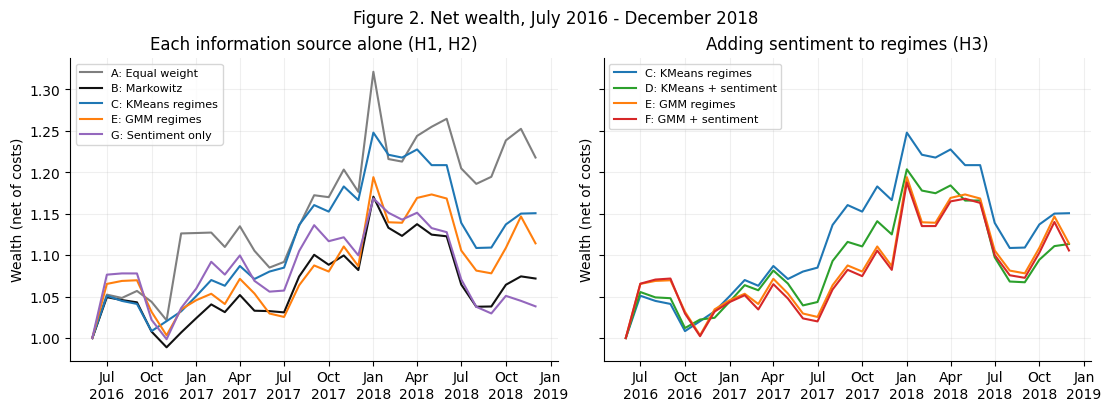

In [9]:
def sharpe(returns):
    return np.sqrt(12) * returns.mean() / returns.std(ddof=1)

summary = pd.DataFrame({key: metrics(net[key], paths[key].turnover) for key in NAMES}).T
monthly_sr = summary.Sharpe_rf0 / np.sqrt(12)
summary["Lo SE"] = np.sqrt(12 * (1 + monthly_sr**2 / 2) / len(test_dates))
summary["t-stat"] = summary.Sharpe_rf0 / summary["Lo SE"]
table = summary[["Sharpe_rf0", "Lo SE", "t-stat", "CAGR", "annualized_vol", "max_drawdown", "mean_monthly_turnover"]]
table.index = [f"{key}: {DESCRIPTIONS[key]}" for key in NAMES]
table.columns = ["Sharpe", "Lo SE", "t-stat", "CAGR", "Volatility", "Max drawdown", "Turnover / month"]
formats = {"Sharpe": "{:.2f}", "Lo SE": "{:.2f}", "t-stat": "{:.2f}", "CAGR": "{:.1%}",
           "Volatility": "{:.1%}", "Max drawdown": "{:.1%}", "Turnover / month": "{:.1%}"}
display(table.apply(lambda col: col.map(formats[col.name].format)))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True, layout="constrained")
for ax, keys, title in [(axes[0], "ABCEG", "Each information source alone (H1, H2)"),
                        (axes[1], "CDEF", "Adding sentiment to regimes (H3)")]:
    for key in keys:
        ax.plot(wealth.index, wealth[key], color=COLORS[key], label=f"{key}: {DESCRIPTIONS[key]}")
    ax.set(title=title, ylabel="Wealth (net of costs)")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
    ax.legend(fontsize=8, loc="upper left")
fig.suptitle("Figure 2. Net wealth, July 2016 - December 2018")
plt.show()

KMeans regimes (C) have the highest observed Sharpe ratio, 0.68, narrowly above equal weighting (A) at 0.64. Equal weighting nevertheless has the highest CAGR, 8.2%, alongside higher volatility. Markowitz (B) has a Sharpe ratio of 0.35, ahead only of sentiment alone (G). Under the i.i.d.-normal approximation, standard errors are about 0.63–0.64 and all reported test statistics are below 1.1. None rejects a zero Sharpe ratio at conventional levels under that approximation. The paired comparisons below address the hypotheses directly while accounting for dependence between strategies.

### 4.2 Hypothesis tests

,Sharpe difference,95% low,95% high,99% low,99% high
H1 C−B KMeans regimes vs Markowitz,0.335,0.041,0.808,-0.038,0.904
H1 E−B GMM regimes vs Markowitz,0.092,-0.357,0.433,-0.480,0.546
H2 G−B Sentiment vs Markowitz,-0.151,-0.492,0.147,-0.586,0.260
H3 D−C Sentiment added to KMeans,-0.168,-0.633,0.062,-0.791,0.102
H3 F−E Sentiment added to GMM,-0.028,-0.081,0.010,-0.105,0.015


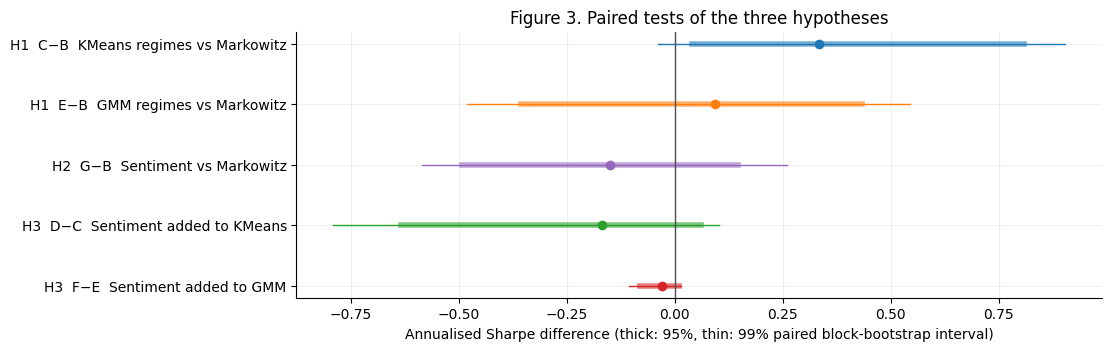

In [10]:
PAIRS = {"H1  C−B  KMeans regimes vs Markowitz": ("C", "B"), "H1  E−B  GMM regimes vs Markowitz": ("E", "B"),
         "H2  G−B  Sentiment vs Markowitz": ("G", "B"), "H3  D−C  Sentiment added to KMeans": ("D", "C"),
         "H3  F−E  Sentiment added to GMM": ("F", "E")}

def paired_bootstrap(returns, pairs, block=6, replications=1000):
    rng = np.random.default_rng(SEED)
    n, draws = len(returns), []
    for _ in range(replications):
        starts = rng.integers(0, n, size=int(np.ceil(n / block)))
        idx = np.concatenate([(s + np.arange(block)) % n for s in starts])[:n]
        sr = sharpe(returns.iloc[idx])
        draws.append([sr[a] - sr[b] for a, b in pairs.values()])
    draws, observed = np.array(draws), sharpe(returns)
    return pd.DataFrame({"Sharpe difference": [observed[a] - observed[b] for a, b in pairs.values()],
                         "95% low": np.quantile(draws, .025, axis=0), "95% high": np.quantile(draws, .975, axis=0),
                         "99% low": np.quantile(draws, .005, axis=0), "99% high": np.quantile(draws, .995, axis=0)},
                        index=list(pairs))

tests = paired_bootstrap(net, PAIRS)
display(tests.round(3))

fig, ax = plt.subplots(figsize=(11, 3.4), layout="constrained")
for i, (name, row) in enumerate(tests.iterrows()):
    color = COLORS[PAIRS[name][0]]
    ax.plot([row["99% low"], row["99% high"]], [i, i], color=color, linewidth=1)
    ax.plot([row["95% low"], row["95% high"]], [i, i], color=color, linewidth=4, alpha=.6)
    ax.scatter(row["Sharpe difference"], i, color=color, zorder=3)
ax.axvline(0, color=".3", linewidth=1)
ax.set_yticks(range(len(tests)), tests.index)
ax.invert_yaxis()
ax.set(xlabel="Annualised Sharpe difference (thick: 95%, thin: 99% paired block-bootstrap interval)",
       title="Figure 3. Paired tests of the three hypotheses")
plt.show()

Only C−B has a 95% interval excluding zero. Its Bonferroni-adjusted 99% interval, [−0.04, 0.90], includes zero, so H1 receives suggestive but inconclusive support from KMeans. GMM's positive difference is also uncertain. All three sentiment contrasts have negative point estimates and intervals containing zero: they provide no evidence of improvement, but do not establish a general harmful effect. The narrow F−E interval is consistent with the small changes in GMM allocations and returns.

### 4.3 Accounting attribution of return differences
The optimised portfolios all average 59–60% in gold, so their return differences mainly arise from the other holdings. The next table locates these differences using each asset's contribution relative to Markowitz, $12\cdot\overline{(w_{i,t}-w^B_{i,t})r_{i,t}}$. These sum to the annualised arithmetic **gross return** difference, not the CAGR or Sharpe difference.

Following the course's attribution approach, each portfolio's gross return is also split into a **tilt** component, based on exponentially averaged target weights with a 12-month half-life, and a **timing** residual, based on deviations from that tilt. These two columns describe each strategy's own return, rather than its advantage over B.

In [11]:
r_test = ret.loc[test_dates]
drivers = pd.DataFrame({key: ((weights[key] - weights["B"]) * r_test).mean() * 12 for key in NAMES}).T
drivers.columns = ["Brent", "US gas", "Gold", "Silver", "Copper"]
drivers["Total vs B"] = drivers.sum(axis=1)
for key in NAMES:
    tilt = weights[key].ewm(halflife=12).mean()
    drivers.loc[key, "Tilt return"] = (tilt * r_test).sum(axis=1).mean() * 12
    drivers.loc[key, "Timing return"] = ((weights[key] - tilt) * r_test).sum(axis=1).mean() * 12
drivers["Mean gold weight"] = [weights[key].gold.mean() for key in NAMES]
drivers.index = [f"{key}: {DESCRIPTIONS[key]}" for key in NAMES]
display(drivers.apply(lambda col: col.map(("{:.0%}" if col.name == "Mean gold weight" else "{:+.1%}").format)))

,Brent,US gas,Gold,Silver,Copper,Total vs B,Tilt return,Timing return,Mean gold weight
A: Equal weight,+1.6%,+3.3%,+0.1%,-0.6%,+1.1%,+5.6%,+8.9%,+0.0%,20%
B: Markowitz,+0.0%,+0.0%,+0.0%,+0.0%,+0.0%,+0.0%,+4.1%,-0.8%,60%
C: KMeans regimes,+0.9%,-0.2%,-0.1%,+0.3%,+1.9%,+2.9%,+5.5%,+0.7%,59%
D: KMeans + sentiment,+0.1%,-0.1%,-0.1%,+0.3%,+1.6%,+1.7%,+5.5%,-0.5%,59%
E: GMM regimes,+0.3%,+1.4%,+0.0%,+0.2%,+0.1%,+2.0%,+5.9%,-0.7%,60%
F: GMM + sentiment,-0.1%,+1.3%,-0.0%,+0.2%,+0.2%,+1.7%,+6.0%,-1.0%,60%
G: Sentiment only,+0.3%,-0.5%,-0.1%,+0.2%,-0.7%,-0.9%,+4.1%,-1.8%,59%


C's gross return advantage over B is 2.9 percentage points per year, with the largest contributions from copper (+1.9 points) and Brent (+0.9). Its timing residual is positive (+0.7% per year), compared with −0.8% for B. The other conditional portfolios have negative timing residuals; G's is −1.8%. Equal weighting's advantage over B comes mainly from natural gas (+3.3 points) and Brent (+1.6).

These are accounting decompositions of realised gross returns. They identify which holdings contributed and how returns divide between smooth and residual positions; they neither explain why a model chose those weights nor establish predictive or market-timing skill.

### 4.4 Lead-lag correlations of the sentiment signal
We relate $S_t$ to commodity price changes $r_{i,t+h}$ over the April 2006 – December 2018 signal sample, including later returns where $h>0$. Negative $h$ refers to earlier returns; positive $h$ to later returns. Under the backtest's lag, sentiment can inform allocations only from $h=2$ onward. This full-sample diagnostic is descriptive, not an independent predictive test.

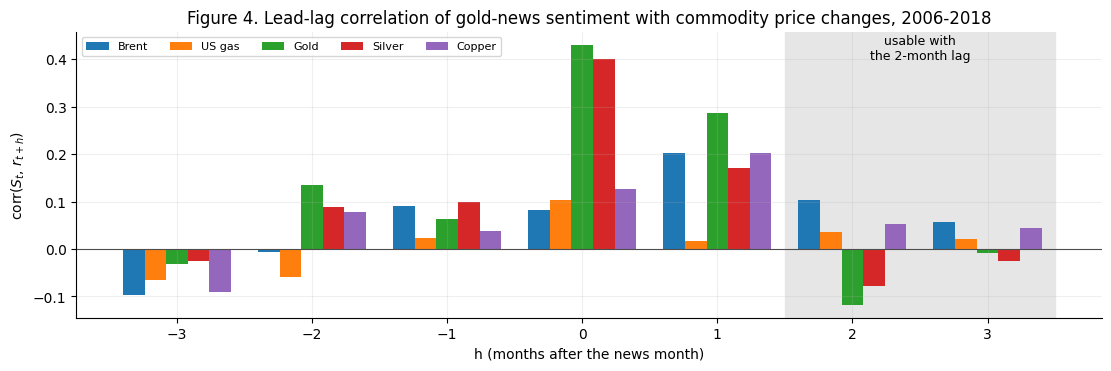

,-3,-2,-1,0,1,2,3
brent,-0.10,-0.01,0.09,0.08,0.20,0.10,0.06
natural_gas_us,-0.06,-0.06,0.02,0.10,0.02,0.04,0.02
gold,-0.03,0.13,0.06,0.43,0.29,-0.12,-0.01
silver,-0.03,0.09,0.10,0.40,0.17,-0.08,-0.03
copper,-0.09,0.08,0.04,0.13,0.20,0.05,0.04


In [12]:
lead_lag = pd.DataFrame({h: {asset: S.corr(ret[asset].shift(-h).reindex(common)) for asset in ret.columns}
                         for h in range(-3, 4)}).T
fig, ax = plt.subplots(figsize=(11, 3.6), layout="constrained")
width = .16
for i, asset in enumerate(ret.columns):
    ax.bar(lead_lag.index + (i - 2) * width, lead_lag[asset], width,
           label={"brent": "Brent", "natural_gas_us": "US gas"}.get(asset, asset.capitalize()))
ax.axvspan(1.5, 3.5, color=".9", zorder=0)
ax.text(2.5, .4, "usable with\nthe 2-month lag", ha="center", fontsize=9)
ax.axhline(0, color=".3", linewidth=.8)
ax.set(xlabel="h (months after the news month)", ylabel="corr($S_t$, $r_{t+h}$)",
       title="Figure 4. Lead-lag correlation of gold-news sentiment with commodity price changes, 2006-2018")
ax.legend(ncol=5, fontsize=8, loc="upper left")
plt.show()
display(lead_lag.T.round(2))

The largest gold and silver correlations occur in the news month (0.43 and 0.40). Gold's correlation remains positive one month later (0.29), but is −0.12 at $h=2$; the other commodities' correlations at that horizon are at most 0.10 in absolute value. Thus the observed linear association is weak at the first permitted allocation horizon. Monthly averaging may contribute to adjacent-month correlations, but this calculation cannot isolate that mechanism. Nor does it rule out nonlinear information or explain the portfolio results.

## 5. Robustness and limitations
### 5.1 Costs, bootstrap block length and the sentiment threshold
We reprice the existing target weights at 0 and 25 bp, vary bootstrap blocks to 3 and 12 months at the baseline 10 bp cost, and rerun G with a zero sentiment threshold. These checks assess sensitivity to specific conventions.

In [13]:
short = {name.split("  ")[1]: pair for name, pair in PAIRS.items()}
rows = {}
for fee in [0, 10, 25]:
    fee_net = pd.DataFrame({key: backtest(weights[key], fee).net_return for key in NAMES})
    s = sharpe(fee_net)
    rows[f"Δ Sharpe, {fee} bp"] = {p: s[a] - s[b] for p, (a, b) in short.items()}
robust = pd.DataFrame(rows)
for block in [3, 6, 12]:
    b = paired_bootstrap(net, short, block=block)
    robust[f"95% interval, {block}-month blocks"] = [f"[{lo:+.2f}, {hi:+.2f}]" for lo, hi in zip(b["95% low"], b["95% high"])]
display(robust.round(3))

weights_g0, _ = allocate(ret, {"G": sentiment_states(0.0)}, test_dates, MODEL_END)
net_g0 = backtest(weights_g0["G"], FEE_BPS).net_return
print(f"G with zero threshold: Sharpe {sharpe(net_g0):.2f} (median threshold {sharpe(net['G']):.2f}; Markowitz {sharpe(net['B']):.2f})")

,"Δ Sharpe, 0 bp","Δ Sharpe, 10 bp","Δ Sharpe, 25 bp","95% interval, 3-month blocks","95% interval, 6-month blocks","95% interval, 12-month blocks"
C−B,0.348,0.335,0.315,"[+0.06, +0.82]","[+0.04, +0.81]","[+0.03, +0.79]"
E−B,0.110,0.092,0.066,"[-0.38, +0.50]","[-0.36, +0.43]","[-0.35, +0.43]"
G−B,-0.130,-0.151,-0.182,"[-0.64, +0.24]","[-0.49, +0.15]","[-0.40, +0.08]"
D−C,-0.158,-0.168,-0.184,"[-0.68, +0.08]","[-0.63, +0.06]","[-0.62, +0.07]"
F−E,-0.027,-0.028,-0.030,"[-0.09, +0.01]","[-0.08, +0.01]","[-0.08, +0.01]"


G with zero threshold: Sharpe 0.32 (median threshold 0.20; Markowitz 0.35)


All five Sharpe differences retain their signs across the three cost levels. At the baseline cost, C−B is the only contrast whose 95% interval excludes zero for every block length examined. These are separate sensitivity checks, not a joint cost-by-block analysis. G's Sharpe rises from 0.20 to 0.32 with a zero threshold but remains below Markowitz's 0.35.

### 5.2 Stability of the regimes
We report development and evaluation-signal occupancy, using the most probable component for GMM; persistence between consecutive evaluation signals; and the development-label adjusted Rand index (ARI) against refits with seeds 0, 7, 21 and 99. ARI measures agreement up to relabelling, with one indicating identical partitions. The final column records fallbacks to unconditional moments in rolling estimation windows.

In [14]:
labels = pd.DataFrame({key: p.to_numpy().argmax(axis=1) for key, p in probabilities.items()}, index=common)
rows = []
for key in "CDEFG":
    k = probabilities[key].shape[1]
    y = labels.loc[signal_dates, key]
    if key in SPECS:
        algorithm, data = SPECS[key]
        ari = [adjusted_rand_score(labels.loc[dev_dates, key],
                                   fit_memberships(data, algorithm, k, dev_dates, seed).loc[dev_dates].to_numpy().argmax(axis=1))
               for seed in [0, 7, 21, 99]]
        seeds = f"{min(ari):.2f}-{max(ari):.2f}"
    else:
        seeds = "deterministic"
    fallback = audit.loc[audit.strategy.eq(key), "fallback_components"]
    rows.append({"strategy": f"{key}: {DESCRIPTIONS[key]}", "k": k,
                 "development months": ", ".join(map(str, labels.loc[dev_dates, key].value_counts().reindex(range(k), fill_value=0))),
                 "evaluation months": ", ".join(map(str, y.value_counts().reindex(range(k), fill_value=0))),
                 "persistence": f"{y.iloc[1:].eq(y.shift(1).iloc[1:]).mean():.0%}", "seed ARI": seeds,
                 "states on fallback": (f"{fallback.max()} state(s), {int(fallback.gt(0).sum())}/30 months"
                                        if fallback.max() else "none")})
display(pd.DataFrame(rows).set_index("strategy"))

,k,development months,evaluation months,persistence,seed ARI,states on fallback
strategy,,,,,,
C: KMeans regimes,3,"62, 51, 4","26, 4, 0",79%,0.93-1.00,"1 state(s), 30/30 months"
D: KMeans + sentiment,3,"54, 59, 4","6, 24, 0",66%,0.87-1.00,"1 state(s), 30/30 months"
E: GMM regimes,4,"12, 53, 12, 40","0, 18, 0, 12",62%,0.63-0.81,"1 state(s), 30/30 months"
F: GMM + sentiment,4,"12, 52, 41, 12","0, 18, 12, 0",62%,0.47-0.81,"1 state(s), 30/30 months"
G: Sentiment only,2,"59, 58","20, 10",55%,deterministic,none


The selected KMeans model has a low validation silhouette (0.17). Both KMeans development refits contain a four-month state absent from evaluation signals; each GMM has two components with no most-probable assignments there. Separately, the rolling effective-size rule triggers one fallback component in every month for C–F. Zero hard occupancy is not equivalent to zero GMM probability or insufficient historical effective size.

KMeans partitions are more stable across seeds (ARI at least 0.87) than GMM partitions (0.47–0.81). Sentiment changes several KMeans assignments. The GMM evaluation partitions are identical up to relabelling, as checked in Notebook 05, although their probabilities differ. Sparse occupancy and seed sensitivity limit the economic interpretation of these states.

### 5.3 Later-period evaluation of H1: March 2021 – December 2025
The news sample does not cover this later period, but market-only regimes can still be evaluated. We repeat the selection procedure with training on April 2006 – December 2015 and validation on January 2016 – December 2020. Scalers and regime models are then refitted through December 2020 and frozen for the 58 evaluation months. The rolling moment, allocation and cost rules remain unchanged. This evaluates newly selected and refitted models, not the original fitted models transferred to another period.

In [15]:
X2 = X_all.loc[START:"2025-12"]
model_end_2 = pd.Timestamp("2020-12-01")
test_dates_2 = pd.date_range("2021-03-01", "2025-12-01", freq="MS")
counts_2, _ = select_counts(X2, X2.loc[:"2015-12"].index, X2.loc["2016":"2020"].index)
memberships_2 = {key: fit_memberships(X2, alg, counts_2[alg], X2.loc[:model_end_2].index)
                 for key, alg in [("C", "KMeans"), ("E", "GMM")]}
weights_2, _ = allocate(ret, memberships_2, test_dates_2, model_end_2)
net_2 = pd.DataFrame({key: backtest(w, FEE_BPS).net_return for key, w in weights_2.items()})
second = paired_bootstrap(net_2, {"C−B KMeans regimes vs Markowitz": ("C", "B"),
                                  "E−B GMM regimes vs Markowitz": ("E", "B")})
second.insert(0, "Markowitz Sharpe", sharpe(net_2["B"]))
second.insert(1, "Regime Sharpe", [sharpe(net_2["C"]), sharpe(net_2["E"])])
print("Selected counts on the later sample:", counts_2)
display(second.round(3))

Selected counts on the later sample: {'KMeans': 4, 'GMM': 4}


,Markowitz Sharpe,Regime Sharpe,Sharpe difference,95% low,95% high,99% low,99% high
C−B KMeans regimes vs Markowitz,1.145,1.041,-0.104,-0.368,0.097,-0.416,0.155
E−B GMM regimes vs Markowitz,1.145,0.882,-0.263,-0.584,0.005,-0.658,0.082


Both later-period regime portfolios have lower observed Sharpe ratios than Markowitz: differences are −0.10 for KMeans and −0.26 for GMM, with both 95% intervals including zero. The selection procedure now chooses four states for each algorithm. The earlier KMeans advantage is therefore not reproduced by the refitted procedure, weakening the case for a consistent benefit across periods without establishing general underperformance.

Neither evaluation period was completely untouched during the broader research process. Chronological fitting limits direct use of later observations, but these results remain retrospective evaluations rather than independent confirmation.

### 5.4 Computational checks
For each initial-period evaluation month, returns and memberships after the information cutoff are replaced with random values; recomputed allocations must remain unchanged. Backtest cash flows are also rebuilt independently. These checks test allocation timing and accounting conditional on the fitted memberships, not historical data availability or the full model-selection process.

In [16]:
rng = np.random.default_rng(2026)
for date in test_dates:
    cutoff = date - pd.DateOffset(months=LAG)
    fake_ret = ret.copy()
    future = fake_ret.index > cutoff
    fake_ret.loc[future] = rng.uniform(-.4, .5, size=(future.sum(), ret.shape[1]))
    fake_p = {}
    for key, p in probabilities.items():
        fake_p[key] = p.copy()
        fake_p[key].loc[p.index > cutoff] = rng.dirichlet(np.ones(p.shape[1]), size=(p.index > cutoff).sum())
    replay, _ = allocate(fake_ret, fake_p, pd.DatetimeIndex([date]), MODEL_END)
    for key in NAMES:
        np.testing.assert_allclose(replay[key].loc[date], weights[key].loc[date], rtol=0, atol=1e-10)

for key, w in weights.items():
    r = ret.loc[test_dates, w.columns]
    gross = (w * r).sum(axis=1)
    drifted = w.mul(1 + r).div(1 + gross, axis=0).shift(1).fillna(0)
    turnover = (w - drifted).abs().sum(axis=1)
    np.testing.assert_allclose(net[key], (1 - FEE_BPS / 1e4 * turnover) * (1 + gross) - 1, atol=1e-12)
print("PASS: future data cannot change any of the 30 x 7 allocations; cash flows reconcile.")

PASS: future data cannot change any of the 30 x 7 allocations; cash flows reconcile.


## 6. Conclusion
The evidence does not establish a reliable improvement over constrained Markowitz allocation from either information source. KMeans achieves the highest Sharpe ratio in July 2016 – December 2018 (0.68 versus 0.35), but its gain does not survive the five-comparison adjustment and is not reproduced by the later refitted procedure. Sentiment lowers all three relevant observed Sharpe differences, with intervals including zero. Its weak linear association at the two-month horizon is consistent with these results, without explaining them.

**Limitations.** The backtest uses World Bank monthly-average price changes, which omit futures roll yield, collateral return and executable prices. Revised snapshots are not point-in-time vintages: the dollar-index methodology, for example, was introduced in February 2019 and backfilled. A two-month lag cannot make these data historically available. The short initial evaluation, sparse regimes, model instability and prior inspection of both periods further limit inference. News concerns gold alone, despite its large average weight in the optimised portfolios.

**Further work.** A stronger test would combine futures total returns and historical data vintages with a longer, broader news corpus, potentially separating forward-looking headlines, and reserve genuinely unexamined dates for evaluation.

### References and implementation attribution

- World Bank, *Commodity Price Data (Pink Sheet)*, and FRED series VIXCLS, DTWEXBGS, DGS10 and DGS2; provider links and fixed download hashes appear in Section 2.
- Sinha, A. and Khandait, T. (2020), [*Impact of News on the Commodity Market: Dataset and Results*](https://arxiv.org/abs/2009.04202). SaguaroCapital's pinned redistribution and licence appear in Section 2.2.
- Alternative datasets reviewed for coverage: polibert, [*oil-sentiment-headlines*](https://huggingface.co/datasets/polibert/oil-sentiment-headlines), and newsdata01, [*crude-oil-and-petroleum-market-news-dataset*](https://huggingface.co/datasets/newsdata01/crude-oil-and-petroleum-market-news-dataset).
- Lo, A. W. (2002), [*The Statistics of Sharpe Ratios*](https://doi.org/10.2469/faj.v58.n4.2453), *Financial Analysts Journal*, 58(4), 36–52.
- von Beschwitz, B., Collins, C. G. and Datta, D. D. (2019), [*Revisions to the Federal Reserve Dollar Indexes*](https://www.federalreserve.gov/econres/notes/feds-notes/revisions-to-the-federal-reserve-dollar-indexes-20190115.html), Federal Reserve Board.
- Champonnois, S. (2026), [*Machine-learning for Portfolio Management and Trading: An Introduction with Scikit-Learn*](https://github.com/schampon/skfin/blob/master/book/book.pdf), Chapters 4 (backtesting), 8–9 (covariance shrinkage), 13 (tilt and timing), 15 (transaction costs), 27 (performance metrics) and 30 (research presentation).
- Champonnois, S., [*ML for Portfolio Management and Trading — course notebooks*](https://github.com/schampon/skfin/tree/master/nbs): `10_Mean_variance_estimators`, `11_Backtesting`, `19_Hyperparameter_optimisation`, `30_Transaction_cost`, `41_Timing_backtest_with_learning`, `46_Text_processing` and `92_Project_template`. These inform allocation, chronological evaluation, text aggregation and presentation; this project retains its own allocation and cost conventions.
- Jdey, O. and Rou, S., project notebooks 01–05. This notebook builds on their commodity/FRED features, portfolio functions and news-cleaning rules. All required code is included above; the original notebooks are not runtime dependencies.